# Tracking plant pots over time with SAM3

Takes a range of frames from the CanopyMap dataset, undistorts them, and tracks every plant pot through all of them with SAM3. The pots detected on the **start frame** (already stored in the dataset as `ph_*` columns) seed the tracker, so each pot keeps the same id for the whole run.

Outputs: an overlay video and a `tracks.jsonl` with one polygon per pot per frame.

## Install

`segment-geospatial[samgeo3]` pulls in the right SAM3 prerequisites. The pinned `transformers` build is the one with the SAM3 video tracker. Restart the runtime after this cell.

In [2]:
%pip install "segment-geospatial[samgeo3]==1.4.2"
%pip install transformers==5.0.0rc0 av defisheye
!git clone https://github.com/regularpooria/CanopyMap.git

fatal: destination path 'CanopyMap' already exists and is not an empty directory.


## Login and load the dataset

The dataset needs your HF token. The `ph_*` columns hold the plant holder detections from the YOLOE notebook. If the assert fails, the PR that added them probably isn't merged yet, so pass `revision="refs/pr/<n>"` to `load_dataset`.

In [4]:
from google.colab import userdata
from huggingface_hub import login
from datasets import load_dataset

login(token=userdata.get("HF_KEY"))
ds = load_dataset("regularpooria/canopymap_plants")["train"]
assert "ph_polygons" in ds.column_names, "plant holder columns missing from the dataset"
print(ds)

README.md:   0%|          | 0.00/637 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  507MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  405MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3163 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'channel', 'date', 'time', 'suitable', 'ph_boxes_xyxy', 'ph_conf', 'ph_cls', 'ph_polygons'],
    num_rows: 3163
})


## Settings

`STOP_IDX` is exclusive, like a Python range. `CHUNK` is how many frames go through SAM3 at once. Each chunk is handed the last masks of the previous one, so ids carry across. Lower it if you run out of memory on the T4.

In [6]:
from pathlib import Path

START_IDX = 100
STOP_IDX = 1000
CHUNK = 150
MIN_CONF = 0.1     # drop weak plant holder detections
NMS_IOU = 0.5      # merge duplicate boxes on the start frame
FPS = 3

WORK_DIR = Path("work");    WORK_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
VIDEO_PATH  = OUT_DIR / "tracked.mp4"
TRACKS_PATH = OUT_DIR / "tracks.jsonl"

## Loading and undistorting frames

Same fisheye correction as the detection notebook. `de_fish_eye_image` wants a file path, so each frame takes a quick trip through a temp jpg. Frames come back as RGB arrays.

In [7]:
import cv2
import numpy as np
from tqdm.auto import tqdm
from CanopyMap.src.utils.distortion import de_fish_eye_image

def undistort(i):
    tmp = WORK_DIR / "tmp.jpg"
    ds[i]["image"].convert("RGB").save(tmp)
    return cv2.cvtColor(de_fish_eye_image(str(tmp)), cv2.COLOR_BGR2RGB)

def load_frames(start, stop):
    return np.stack([undistort(i) for i in tqdm(range(start, stop), desc="undistort", leave=False)])

## Parsing the stored detections

`parse_holders` reads one dataset row and returns boxes, confidences and polygons, filtered by confidence and NMS. `assign_ids` then numbers the pots in reading order (top to bottom, left to right), starting at 1. Those ids are what the tracker uses from here on.

In [8]:
import json
import torch
from torchvision.ops import nms

def parse_holders(row, min_conf=MIN_CONF, iou=NMS_IOU):
    boxes = np.asarray(row["ph_boxes_xyxy"], dtype=np.float32).reshape(-1, 4)
    conf = np.asarray(row["ph_conf"], dtype=np.float32)
    polys = [np.asarray(p, dtype=np.float32) for p in json.loads(row["ph_polygons"])]
    if len(polys) != len(boxes):
        polys = [None] * len(boxes)

    keep = np.where(conf >= min_conf)[0]
    if len(keep):
        kept = nms(torch.from_numpy(boxes[keep]), torch.from_numpy(conf[keep]), iou).numpy()
        keep = keep[kept]
    return {"boxes": boxes[keep], "conf": conf[keep], "polygons": [polys[k] for k in keep]}

def assign_ids(holders, row_tol=60):
    b = holders["boxes"]
    cx, cy = (b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2
    order = np.lexsort((cx, cy // row_tol))
    out = {k: [v[i] for i in order] for k, v in holders.items()}
    out["boxes"] = b[order]
    out["ids"] = np.arange(1, len(order) + 1)
    return out

holders = assign_ids(parse_holders(ds[START_IDX]))
print(f"{len(holders['ids'])} pots on frame {START_IDX}")

15 pots on frame 100


## Check the start frame

Worth a look before the long run. If pots are missing or doubled, adjust `MIN_CONF` / `NMS_IOU` above and rerun from the settings cell.

undistort:   0%|          | 0/1 [00:00<?, ?it/s]

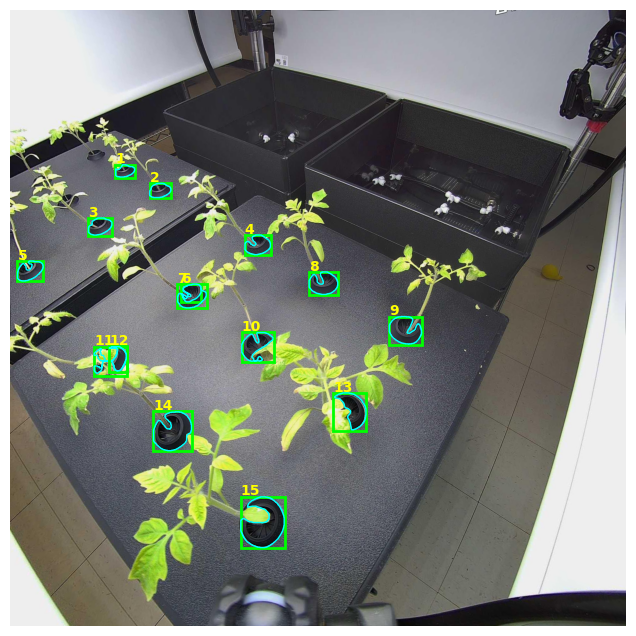

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

start_frame = load_frames(START_IDX, START_IDX + 1)[0]

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(start_frame)
for pid, (x1, y1, x2, y2), poly in zip(holders["ids"], holders["boxes"], holders["polygons"]):
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2))
    if poly is not None:
        ax.add_patch(patches.Polygon(poly, fill=False, edgecolor="cyan", linewidth=1))
    ax.text(x1, y1 - 4, str(pid), color="yellow", weight="bold")
ax.axis("off")
plt.show()

## Load SAM3

This is the tracker variant, which takes box or mask prompts tied to an object id. fp16 because the T4 has no real bf16 support.

In [12]:
from transformers import Sam3TrackerVideoModel, Sam3TrackerVideoProcessor

DEVICE, DTYPE = "cuda", torch.float16
model = Sam3TrackerVideoModel.from_pretrained("facebook/sam3").to(DEVICE, dtype=DTYPE).eval()
processor = Sam3TrackerVideoProcessor.from_pretrained("facebook/sam3")

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/845 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

## Output helpers

Masks are drawn onto the frame with the pot id, and each mask is also reduced to a simplified polygon plus bbox and area for `tracks.jsonl`. The video is written frame by frame so nothing piles up in memory.

In [13]:
import av

def color_for(pid):
    hsv = np.uint8([[[int(((pid * 0.618) % 1.0) * 179), 220, 255]]])
    return tuple(int(c) for c in cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0])

def draw_tracks(frame, masks, ids, alpha=0.45):
    out = frame.copy()
    scale = frame.shape[0] / 1080
    for m, pid in zip(masks, ids):
        if not m.any():
            continue
        color = color_for(pid)
        out[m] = (out[m] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, color, 2)
        ys, xs = np.nonzero(m)
        cv2.putText(out, str(pid), (int(xs.mean()), int(ys.mean())),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2 * scale, (255, 255, 255), max(2, int(3 * scale)))
    return out

def mask_to_track(m, pid):
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    poly = cv2.approxPolyDP(max(cnts, key=cv2.contourArea), 1.5, True)[:, 0]
    x, y, w, h = cv2.boundingRect(poly)
    return {"id": int(pid), "area": int(m.sum()), "bbox": [x, y, x + w, y + h],
            "polygon": poly.round(1).tolist()}

def open_writer(path, w, h, fps):
    container = av.open(str(path), mode="w")
    stream = container.add_stream("libx264", rate=fps)
    stream.width, stream.height = w - w % 2, h - h % 2
    stream.pix_fmt = "yuv420p"
    stream.options = {"crf": "20"}
    return container, stream

def write_frame(container, stream, frame):
    frame = np.ascontiguousarray(frame[:stream.height, :stream.width])
    for p in stream.encode(av.VideoFrame.from_ndarray(frame, format="rgb24")):
        container.mux(p)

## Track every frame

The first chunk is seeded with the start frame boxes under the ids from `assign_ids`. Every later chunk is seeded with each pot's most recent mask, so the id follows the same plant across chunk boundaries. Per frame we write the overlay and the polygons, then free the chunk before loading the next.

In [16]:
import gc

ids = [int(i) for i in holders["ids"]]
boxes = holders["boxes"].tolist()
last_mask = {}
container = stream = None

with open(TRACKS_PATH, "w") as tracks_f, torch.inference_mode(), torch.autocast("cuda", dtype=DTYPE):
    for c_start in range(START_IDX, STOP_IDX, CHUNK):
        c_stop = min(c_start + CHUNK, STOP_IDX)
        frames = load_frames(c_start, c_stop)
        H, W = frames.shape[1:3]
        if container is None:
            container, stream = open_writer(VIDEO_PATH, W, H, FPS)

        session = processor.init_video_session(
            video=frames, inference_device=DEVICE, processing_device="cpu",
            video_storage_device="cpu", dtype=DTYPE,
        )
        if c_start == START_IDX:
            processor.add_inputs_to_inference_session(
                session, frame_idx=0, obj_ids=ids, input_boxes=[boxes])
        else:
            processor.add_inputs_to_inference_session(
                session, frame_idx=0, obj_ids=list(last_mask), input_masks=list(last_mask.values()))

        for out in tqdm(model.propagate_in_video_iterator(session, start_frame_idx=0), total=len(frames), desc=f"frames {c_start}-{c_stop - 1}"):
            logits = processor.post_process_masks([out.pred_masks], original_sizes=[[H, W]], binarize=False)[0]
            masks = (logits[:, 0] > 0).cpu().numpy()

            tracks = []
            for m, pid in zip(masks, out.object_ids):
                if m.any():
                    last_mask[int(pid)] = m
                    tracks.append(mask_to_track(m, pid))
            tracks_f.write(json.dumps({"frame": c_start + out.frame_idx, "tracks": tracks}) + "\n")
            write_frame(container, stream, draw_tracks(frames[out.frame_idx], masks, out.object_ids))

        del session, frames
        gc.collect()
        torch.cuda.empty_cache()

for p in stream.encode():
    container.mux(p)
container.close()
print("done:", VIDEO_PATH, TRACKS_PATH)

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 100-249:   0%|          | 0/150 [00:00<?, ?it/s]

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 250-399:   0%|          | 0/150 [00:00<?, ?it/s]

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 400-549:   0%|          | 0/150 [00:00<?, ?it/s]

... (3 outputs left out)

frames 700-849:   0%|          | 0/150 [00:00<?, ?it/s]

undistort:   0%|          | 0/150 [00:00<?, ?it/s]

frames 850-999:   0%|          | 0/150 [00:00<?, ?it/s]

done: outputs/tracked.mp4 outputs/tracks.jsonl


In [17]:
from google.colab import files

# Replace with your actual file path
files.download('/content/outputs/tracked.mp4')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Results

Quick look at the overlay video, plus how many frames each pot id was actually found in. An id with low coverage usually means the tracker lost that plant, or it was occluded.

In [ ]:
from collections import Counter
from IPython.display import Video

seen = Counter()
with open(TRACKS_PATH) as f:
    n_frames = 0
    for line in f:
        n_frames += 1
        seen.update(t["id"] for t in json.loads(line)["tracks"])

for pid in ids:
    print(f"pot {pid:>2}: found in {seen[pid]}/{n_frames} frames")

Video(str(VIDEO_PATH), embed=True, width=720)